# Gradient Boosting / Regressor

**Type:** Guided machine-learning practice notebook (course-based study).  
**Purpose:** Explore the dataset and the modeling/preprocessing operations illustrated in the code below.  
**Data in this folder:** `concrete_data.csv`.  
**Methods referenced:** `DecisionTreeRegressor`, `GradientBoostingRegressor`.

> **Reproducibility note:** Run cells sequentially from this notebook’s folder. Outputs are historical study results, not independently validated benchmarks. The data files were supplied with the original archive; see `DATA_SOURCES.md` at the repository root for provenance checks.


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

In [2]:
df = pd.read_csv("concrete_data.csv")

In [3]:
df.head(10)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
5,266.0,114.0,0.0,228.0,0.0,932.0,670.0,90,47.03
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,365,43.70
7,380.0,95.0,0.0,228.0,0.0,932.0,594.0,28,36.45
8,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28,45.85
9,475.0,0.0,0.0,228.0,0.0,932.0,594.0,28,39.29


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Cement              1030 non-null   float64
 1   Blast Furnace Slag  1030 non-null   float64
 2   Fly Ash             1030 non-null   float64
 3   Water               1030 non-null   float64
 4   Superplasticizer    1030 non-null   float64
 5   Coarse Aggregate    1030 non-null   float64
 6   Fine Aggregate      1030 non-null   float64
 7   Age                 1030 non-null   int64  
 8   Strength            1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [5]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


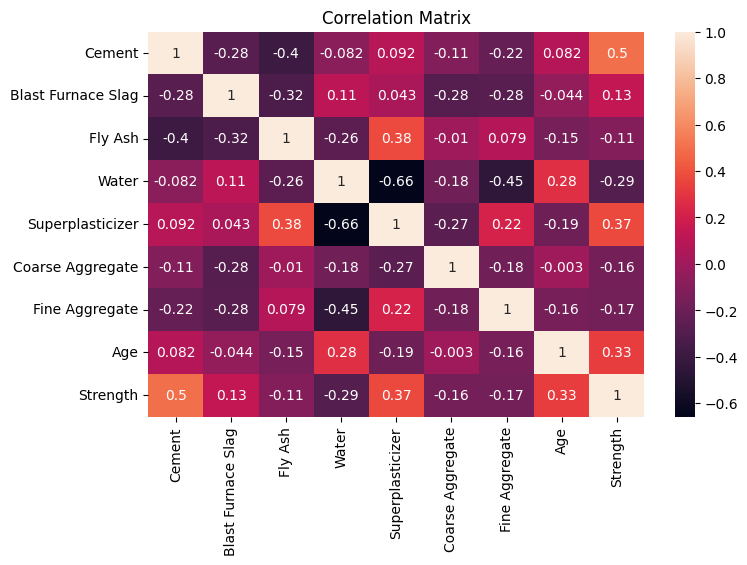

In [6]:
plt.figure(figsize = (8, 5))
sns.heatmap(data = df.corr(numeric_only=True), annot = True)
plt.title("Correlation Matrix")
plt.show()

In [7]:
df.head(10)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
5,266.0,114.0,0.0,228.0,0.0,932.0,670.0,90,47.03
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,365,43.70
7,380.0,95.0,0.0,228.0,0.0,932.0,594.0,28,36.45
8,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28,45.85
9,475.0,0.0,0.0,228.0,0.0,932.0,594.0,28,39.29


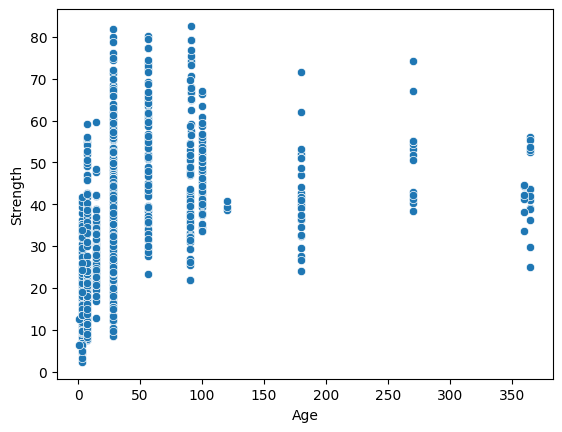

In [8]:
sns.scatterplot(data = df, x = "Age", y = "Strength")
plt.show()

In [9]:
X = df.drop("Strength", axis = 1)
y = df["Strength"]

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

In [11]:
gbr = GradientBoostingRegressor()

In [12]:
gbr.fit(X_train, y_train)
y_pred = gbr.predict(X_test)
print(r2_score(y_test, y_pred))

0.8925425278539731


In [13]:
params = {
    "n_estimators" : [100, 150, 200],
    "max_depth" : [3,4,5],
    "loss" : ["squared_error", "absolute_error", "huber", "quantile"],
    "learning_rate" : [0.01, 0.1, 0.5]
}

In [14]:
grid = GridSearchCV(estimator = GradientBoostingRegressor(), param_grid = params, verbose = 1, n_jobs = -1)

In [15]:
grid.fit(X_train, y_train)
print(grid.best_params_)
y_pred = gbr.predict(X_test)
print(r2_score(y_test, y_pred))

Fitting 5 folds for each of 108 candidates, totalling 540 fits
{'learning_rate': 0.1, 'loss': 'huber', 'max_depth': 4, 'n_estimators': 200}
0.8925425278539731
